In [1]:
# Netflix Data Analysis Project

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", None)

In [3]:
df = pd.read_csv("netflix1.csv")
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [4]:
print("Rows, Columns", df.shape)

Rows, Columns (8790, 10)


In [5]:
df

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"
...,...,...,...,...,...,...,...,...,...,...
8785,s8797,TV Show,Yunus Emre,Not Given,Turkey,1/17/2017,2016,TV-PG,2 Seasons,"International TV Shows, TV Dramas"
8786,s8798,TV Show,Zak Storm,Not Given,United States,9/13/2018,2016,TV-Y7,3 Seasons,Kids' TV
8787,s8801,TV Show,Zindagi Gulzar Hai,Not Given,Pakistan,12/15/2016,2012,TV-PG,1 Season,"International TV Shows, Romantic TV Shows, TV ..."
8788,s8784,TV Show,Yoko,Not Given,Pakistan,6/23/2018,2016,TV-Y,1 Season,Kids' TV


In [6]:
# Column names, data types and how many non-empty values each column has

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8790 non-null   str  
 1   type          8790 non-null   str  
 2   title         8790 non-null   str  
 3   director      8790 non-null   str  
 4   country       8790 non-null   str  
 5   date_added    8790 non-null   str  
 6   release_year  8790 non-null   int64
 7   rating        8790 non-null   str  
 8   duration      8790 non-null   str  
 9   listed_in     8790 non-null   str  
dtypes: int64(1), str(9)
memory usage: 686.8 KB


In [11]:
df.isnull().sum()

show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

In [8]:
# Summary statistics for the numeric columns
df.describe()

,release_year
count,8790.000000
mean,2014.183163
std,8.825466
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


In [9]:
# Data Quality Issues to Note:
# OUTLIER DETECTED:
# min = 1925 (oldest content)
# max = 2021 (newest content)
# This is a 96-year span! A movie from 1925 is extremely unusual for Netflix. 

Action: Investigate this outlier

SyntaxError: invalid syntax (17930757.py, line 7)

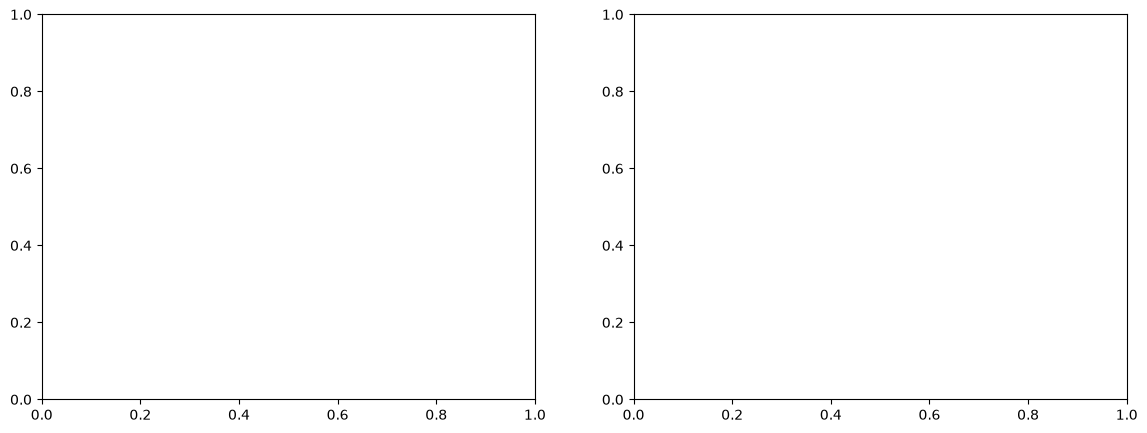

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

In [ ]:
# Find the 1925 entry
print(df[df['release_year'] == 1925])

    show_id     type                              title   director   country  \
421   s4251  TV Show  Pioneers: First Women Filmmakers*  Not Given  Pakistan   

     date_added  release_year rating  duration listed_in  
421  12/30/2018          1925  TV-14  1 Season  TV Shows  


In [ ]:
# Because its a Netflix data analysis, I would remove entries before 2000 because:

# Removes obvious data inconsistencies
# Focuses on Netflix's actual streaming era
# Which is most meaningful for business analysis


In [ ]:
df_cleaned = df[df['release_year'] >= 2000].copy()
print(f"Removed {len(df) - len(df_cleaned)} rows")
print(df_cleaned['release_year'].describe())

Removed 525 rows
count    8265.000000
mean     2015.970236
std         4.345479
min      2000.000000
25%      2015.000000
50%      2017.000000
75%      2019.000000
max      2021.000000
Name: release_year, dtype: float64


In [ ]:
# Find all entries before 2000

old_content = df[df['release_year'] < 2000]
print(f"Found {len(old_content)} entries before 2000:")
print(old_content[['title', 'type', 'release_year', 'date_added']])

Found 525 entries before 2000:
                                    title     type  release_year date_added
4                                 Sankofa    Movie          1993  9/24/2021
29                                  Jeans    Movie          1998  9/21/2021
51                         Minsara Kanavu    Movie          1997  9/21/2021
53                        Avvai Shanmughi    Movie          1996  9/21/2021
60                                   Jaws    Movie          1975  9/16/2021
...                                   ...      ...           ...        ...
8702                             The Bund    Movie          1983  9/20/2018
8743    The Super Mario Bros. Super Show!  TV Show          1989  5/22/2016
8746  The Twilight Zone (Original Series)  TV Show          1963   7/1/2017
8761                           Twin Peaks  TV Show          1990   7/1/2017
8765                        V.R. Troopers  TV Show          1995   1/1/2016

[525 rows x 4 columns]


In [ ]:
#CHECKING FOR MISSING DATA

In [ ]:
# How many values are missing in each column?
print(df_cleaned.isnull().sum())

show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64


In [ ]:
# CHECKING FOR DUPLICATE
print(df_cleaned.duplicated().sum())


0


In [ ]:
# PART TWO IS TO PREPARE THE DATA: Making a copy so the original cleaned one stayed untouched
clean = df_cleaned.copy()
print(clean.head())

  show_id     type                             title         director  \
0      s1    Movie              Dick Johnson Is Dead  Kirsten Johnson   
1      s3  TV Show                         Ganglands  Julien Leclercq   
2      s6  TV Show                     Midnight Mass    Mike Flanagan   
3     s14    Movie  Confessions of an Invisible Girl    Bruno Garotti   
5      s9  TV Show     The Great British Baking Show  Andy Devonshire   

          country date_added  release_year rating   duration  \
0   United States  9/25/2021          2020  PG-13     90 min   
1          France  9/24/2021          2021  TV-MA   1 Season   
2   United States  9/24/2021          2021  TV-MA   1 Season   
3          Brazil  9/22/2021          2021  TV-PG     91 min   
5  United Kingdom  9/24/2021          2021  TV-14  9 Seasons   

                                           listed_in  
0                                      Documentaries  
1  Crime TV Shows, International TV Shows, TV Act...  
2          

In [ ]:
# Encoding: Turning text into numbers
df_cleaned.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
5,s9,TV Show,The Great British Baking Show,Andy Devonshire,United Kingdom,9/24/2021,2021,TV-14,9 Seasons,"British TV Shows, Reality TV"


In [ ]:
df_cleaned

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
5,s9,TV Show,The Great British Baking Show,Andy Devonshire,United Kingdom,9/24/2021,2021,TV-14,9 Seasons,"British TV Shows, Reality TV"
...,...,...,...,...,...,...,...,...,...,...
8785,s8797,TV Show,Yunus Emre,Not Given,Turkey,1/17/2017,2016,TV-PG,2 Seasons,"International TV Shows, TV Dramas"
8786,s8798,TV Show,Zak Storm,Not Given,United States,9/13/2018,2016,TV-Y7,3 Seasons,Kids' TV
8787,s8801,TV Show,Zindagi Gulzar Hai,Not Given,Pakistan,12/15/2016,2012,TV-PG,1 Season,"International TV Shows, Romantic TV Shows, TV ..."
8788,s8784,TV Show,Yoko,Not Given,Pakistan,6/23/2018,2016,TV-Y,1 Season,Kids' TV


In [ ]:
df_encoded = df_cleaned.copy()

In [ ]:
df_encoded

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
5,s9,TV Show,The Great British Baking Show,Andy Devonshire,United Kingdom,9/24/2021,2021,TV-14,9 Seasons,"British TV Shows, Reality TV"
...,...,...,...,...,...,...,...,...,...,...
8785,s8797,TV Show,Yunus Emre,Not Given,Turkey,1/17/2017,2016,TV-PG,2 Seasons,"International TV Shows, TV Dramas"
8786,s8798,TV Show,Zak Storm,Not Given,United States,9/13/2018,2016,TV-Y7,3 Seasons,Kids' TV
8787,s8801,TV Show,Zindagi Gulzar Hai,Not Given,Pakistan,12/15/2016,2012,TV-PG,1 Season,"International TV Shows, Romantic TV Shows, TV ..."
8788,s8784,TV Show,Yoko,Not Given,Pakistan,6/23/2018,2016,TV-Y,1 Season,Kids' TV


In [ ]:
# Data Preprocessing: Encoding categorical variables
# Get all categorical columns
categorical_columns = df_encoded.select_dtypes(include=['object']).columns.tolist()

C:\Users\akinl\AppData\Local\Temp\ipykernel_30956\551558023.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df_encoded.select_dtypes(include=['object']).columns.tolist()


In [ ]:
categorical_columns = df_encoded.select_dtypes(include=['object', 'string']).columns.tolist()

In [ ]:
# Get categorical columns (using the fixed code)
categorical_columns = df_encoded.select_dtypes(include=['object', 'string']).columns.tolist()
print(f"Columns to encode: {categorical_columns}\n")

Columns to encode: ['show_id', 'type', 'title', 'director', 'country', 'date_added', 'rating', 'duration', 'listed_in']



In [ ]:
# Apply one-hot encoding
df_encoded = pd.get_dummies(df_encoded, columns=categorical_columns, drop_first=True)

In [ ]:
print("✅ Encoding complete!")
print(f"New shape: {df_encoded.shape}")
print(f"\nFirst few rows:")
print(df_encoded.head())

✅ Encoding complete!
New shape: (8265, 23268)

First few rows:
   release_year  show_id_s10  show_id_s100  show_id_s1000  show_id_s1001  \
0          2020        False         False          False          False   
1          2021        False         False          False          False   
2          2021        False         False          False          False   
3          2021        False         False          False          False   
5          2021        False         False          False          False   

   show_id_s1002  show_id_s1003  show_id_s1004  show_id_s1005  show_id_s1006  \
0          False          False          False          False          False   
1          False          False          False          False          False   
2          False          False          False          False          False   
3          False          False          False          False          False   
5          False          False          False          False          False   


In [ ]:
# Problem Encountered: Too Many Columns Created!
Your dataset exploded from 10 columns to 23,268 columns! 

The issue: You're encoding show_id which has 8,265 unique values - creating 8,265 separate columns! That's not useful.

In [ ]:
# Start fresh
df_encoded = df_cleaned.copy()

In [ ]:
# Step 1: Drop unnecessary columns
df_encoded = df_encoded.drop(columns=['show_id', 'director', 'country', 'date_added'])

KeyError: "['director', 'country', 'date_added'] not found in axis"

In [ ]:
# See all current columns
print("Current columns in df_encoded:")
print(df_encoded.columns.tolist())

Current columns in df_encoded:
['show_id', 'release_year', 'duration', 'type_TV Show', 'title_#AnneFrank - Parallel Stories', 'title_#FriendButMarried', 'title_#FriendButMarried 2', 'title_#Roxy', 'title_#Rucker50', 'title_#Selfie', 'title_#Selfie 69', 'title_#blackAF', 'title_#cats_the_mewvie', 'title_#realityhigh', "title_'76", "title_'89", 'title_(T)ERROR', 'title_(Un)Well', 'title_1 Chance 2 Dance', 'title_1 Mile to You', 'title_1-Oct', 'title_10 Days in Sun City', 'title_10 jours en or', 'title_10,000 B.C.', 'title_100 Days My Prince', 'title_100 Days Of Solitude', 'title_100 Humans', 'title_100 Meters', 'title_100 Things to do Before High School', "title_100 Years: One Woman's Fight for Justice", 'title_100% Halal', 'title_100% Hotter', 'title_1000 Rupee Note', 'title_12 ROUND GUN', 'title_12 Years Promise', 'title_122', 'title_13 Cameras', 'title_13 Reasons Why', 'title_13 Reasons Why: Beyond the Reasons', 'title_13 Sins', 'title_13TH', 'title_14 Blades', 'title_14 Cameras', 'ti

In [ ]:
# Drop only columns that actually exist
columns_to_drop = ['show_id', 'director', 'country', 'date_added']

In [ ]:
# Filter to only columns that exist
columns_to_drop = [col for col in columns_to_drop if col in df_encoded.columns]
print(f"Dropping these columns: {columns_to_drop}")

Dropping these columns: ['show_id']


In [ ]:
df_encoded = df_encoded.drop(columns=columns_to_drop, errors='ignore')

In [ ]:
print(f"\n✅ Columns dropped!")
print(f"Remaining columns: {df_encoded.columns.tolist()}")
print(f"New shape: {df_encoded.shape}")


✅ Columns dropped!
Remaining columns: ['release_year', 'duration', 'type_TV Show', 'title_#AnneFrank - Parallel Stories', 'title_#FriendButMarried', 'title_#FriendButMarried 2', 'title_#Roxy', 'title_#Rucker50', 'title_#Selfie', 'title_#Selfie 69', 'title_#blackAF', 'title_#cats_the_mewvie', 'title_#realityhigh', "title_'76", "title_'89", 'title_(T)ERROR', 'title_(Un)Well', 'title_1 Chance 2 Dance', 'title_1 Mile to You', 'title_1-Oct', 'title_10 Days in Sun City', 'title_10 jours en or', 'title_10,000 B.C.', 'title_100 Days My Prince', 'title_100 Days Of Solitude', 'title_100 Humans', 'title_100 Meters', 'title_100 Things to do Before High School', "title_100 Years: One Woman's Fight for Justice", 'title_100% Halal', 'title_100% Hotter', 'title_1000 Rupee Note', 'title_12 ROUND GUN', 'title_12 Years Promise', 'title_122', 'title_13 Cameras', 'title_13 Reasons Why', 'title_13 Reasons Why: Beyond the Reasons', 'title_13 Sins', 'title_13TH', 'title_14 Blades', 'title_14 Cameras', 'title

In [ ]:
# START OVER with original cleaned data
df_encoded = df_cleaned.copy()

In [ ]:
print("Original shape:", df_encoded.shape)
print("Original columns:", df_encoded.columns.tolist())

Original shape: (8265, 10)
Original columns: ['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']


In [ ]:
# Step 1: Drop ID and date columns FIRST
df_encoded = df_encoded.drop(columns=['show_id', 'director', 'country', 'date_added'])
print("\nAfter dropping ID columns:", df_encoded.columns.tolist())


After dropping ID columns: ['type', 'title', 'release_year', 'rating', 'duration', 'listed_in']


In [ ]:
# Step 2: Check unique values in each column
print("\nUnique values per column:")
for col in df_encoded.columns:
    print(f"{col}: {df_encoded[col].nunique()}")


Unique values per column:
type: 2
title: 8262
release_year: 22
rating: 14
duration: 205
listed_in: 467


In [ ]:
# Load fresh data
df_encoded = df_cleaned.copy()

In [ ]:
# Keep only the columns you want
df_encoded = df_encoded[['title', 'type', 'release_year', 'rating', 'duration', 'listed_in']]
print("Selected columns:")
print(df_encoded.columns.tolist())
print(f"Shape: {df_encoded.shape}\n")

Selected columns:
['title', 'type', 'release_year', 'rating', 'duration', 'listed_in']
Shape: (8265, 6)



In [ ]:
# Now encode
df_encoded = pd.get_dummies(df_encoded, columns=['type', 'rating'], drop_first=True)

print("✅ Done!")
print(f"Final shape: {df_encoded.shape}")
print(df_encoded.head())

✅ Done!
Final shape: (8265, 18)
                              title  release_year   duration  \
0              Dick Johnson Is Dead          2020     90 min   
1                         Ganglands          2021   1 Season   
2                     Midnight Mass          2021   1 Season   
3  Confessions of an Invisible Girl          2021     91 min   
5     The Great British Baking Show          2021  9 Seasons   

                                           listed_in  type_TV Show  \
0                                      Documentaries         False   
1  Crime TV Shows, International TV Shows, TV Act...          True   
2                 TV Dramas, TV Horror, TV Mysteries          True   
3                 Children & Family Movies, Comedies         False   
5                       British TV Shows, Reality TV          True   

   rating_NC-17  rating_NR  rating_PG  rating_PG-13  rating_R  rating_TV-14  \
0         False      False      False          True     False         False   
1   

In [ ]:
print("Current data ranges:")
print(df_encoded.describe())

Current data ranges:
       release_year
count   8265.000000
mean    2015.970236
std        4.345479
min     2000.000000
25%     2015.000000
50%     2017.000000
75%     2019.000000
max     2021.000000
